# Churn Models

**Goal:** find the model that best ranks customers by churn risk.
**Input:** `features.parquet` from `04_features.ipynb`.# Churn Models

**Goal:** find the model that best ranks customers by churn risk.
**Input:** `features.parquet` from `04_features.ipynb`.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer

# One clean style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folders for the charts and for the saved model
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)


def takeaway(text):
    # Show the takeaway under a chart (same helper as in the other notebooks)
    display(Markdown("**Takeaway:** " + text))

In [2]:
# Load the features (each row = one customer at one snapshot date, with the churn answer)
data = pd.read_parquet("../data/processed/features.parquet")
feature_cols = [c for c in data.columns if c not in ["customer_id", "cutoff", "split", "churn"]]

# Split by time: train = older snapshots, valid = Jun 2011, test = Sep 2011
train = data[data["split"] == "train"]
valid = data[data["split"] == "valid"]
test = data[data["split"] == "test"]

X_train, y_train = train[feature_cols], train["churn"]
X_valid, y_valid = valid[feature_cols], valid["churn"]
X_test, y_test = test[feature_cols], test["churn"]

print("Features:", len(feature_cols))
print("Rows | train:", f"{len(train):,}", "| valid:", f"{len(valid):,}", "| test:", f"{len(test):,}")
print("Churn rate | train:", f"{y_train.mean():.1%}", "| valid:", f"{y_valid.mean():.1%}", "| test:", f"{y_test.mean():.1%}")

Features: 19
Rows | train: 30,885 | valid: 2,629 | test: 2,783
Churn rate | train: 52.0% | valid: 50.3% | test: 38.3%


## Model 1: a simple rule (the baseline)

In [3]:
# The simple rule: the longer a customer has been silent, the higher the risk score
score_rule = X_valid["recency_days"]

# The 10% of customers with the highest score (built-in nlargest)
top10 = valid.nlargest(int(len(valid) * 0.10), "recency_days")

# A table where we will collect the result of every model
results = pd.DataFrame(columns=["roc_auc", "pr_auc", "top10_churn_rate"])
results.loc["Recency rule"] = [
    roc_auc_score(y_valid, score_rule),              # 0.5 = random guessing, 1.0 = perfect ranking
    average_precision_score(y_valid, score_rule),    # random guessing would give the churn rate
    top10["churn"].mean(),                           # of the 10% flagged, how many really churn
]
print("Valid churn rate (random guessing):", round(y_valid.mean(), 3))
results.round(3)

Valid churn rate (random guessing): 0.503


,roc_auc,pr_auc,top10_churn_rate
Recency rule,0.653,0.632,0.698


## Model 2: logistic regression

In [4]:
# Steps in a row: fill empty values with the median, make skewed features less skewed and put them
# on the same scale, then fit the logistic regression
logit = make_pipeline(
    SimpleImputer(strategy="median"),
    PowerTransformer(),
    LogisticRegression(max_iter=1000),
)
logit.fit(X_train, y_train)

# Risk score = the predicted probability of churn (column 1 of predict_proba)
score_logit = logit.predict_proba(X_valid)[:, 1]
top10 = valid.assign(score=score_logit).nlargest(int(len(valid) * 0.10), "score")

results.loc["Logistic regression"] = [
    roc_auc_score(y_valid, score_logit),
    average_precision_score(y_valid, score_logit),
    top10["churn"].mean(),
]
results.round(3)

,roc_auc,pr_auc,top10_churn_rate
Recency rule,0.653,0.632,0.698
Logistic regression,0.772,0.755,0.874


## Model 3: LightGBM (a tree model that finds complex patterns)

In [5]:
# LightGBM builds many small decision trees, each one correcting the mistakes of the previous ones.
# The settings are modest on purpose, to avoid memorizing the training data (overfitting).
lgbm = LGBMClassifier(
    n_estimators=300,        # number of small trees
    learning_rate=0.05,      # how much each new tree is allowed to correct
    num_leaves=15,           # keeps every tree small
    min_child_samples=50,    # a rule must be based on at least 50 customers
    subsample=0.8,           # each tree sees 80% of the rows
    subsample_freq=1,
    colsample_bytree=0.8,    # each tree sees 80% of the features
    importance_type="gain",  # how feature importance is measured later
    random_state=42,         # same result every time
    verbose=-1,              # no log messages
)
lgbm.fit(X_train, y_train)

# Risk score on the valid snapshot
score_lgbm = lgbm.predict_proba(X_valid)[:, 1]
top10 = valid.assign(score=score_lgbm).nlargest(int(len(valid) * 0.10), "score")

results.loc["LightGBM"] = [
    roc_auc_score(y_valid, score_lgbm),
    average_precision_score(y_valid, score_lgbm),
    top10["churn"].mean(),
]

# Overfitting check: a model that memorizes scores much higher on the data it learned from
print("ROC-AUC on train:", round(roc_auc_score(y_train, lgbm.predict_proba(X_train)[:, 1]), 3))
print("ROC-AUC on valid:", round(roc_auc_score(y_valid, score_lgbm), 3))
results.round(3)

ROC-AUC on train: 0.821
ROC-AUC on valid: 0.773


,roc_auc,pr_auc,top10_churn_rate
Recency rule,0.653,0.632,0.698
Logistic regression,0.772,0.755,0.874
LightGBM,0.773,0.754,0.851


## Compare the models on the valid snapshot

In [6]:
# How many times better than random guessing is the top 10%?
results["top10_lift"] = results["top10_churn_rate"] / y_valid.mean()
display(results.round(3))

gap_auc = results.loc["LightGBM", "roc_auc"] - results.loc["Logistic regression", "roc_auc"]
takeaway(
    f"Both trained models are far better than the simple rule (ROC-AUC {results.loc['Logistic regression', 'roc_auc']:.3f} and "
    f"{results.loc['LightGBM', 'roc_auc']:.3f} against {results.loc['Recency rule', 'roc_auc']:.3f}). "
    f"LightGBM is only {gap_auc:+.3f} ROC-AUC away from the logistic regression, which is no real difference. "
    "When two models perform the same, we choose the simpler one: the logistic regression."
)

# The chosen model
final_name = "Logistic regression"

,roc_auc,pr_auc,top10_churn_rate,top10_lift
Recency rule,0.653,0.632,0.698,1.389
Logistic regression,0.772,0.755,0.874,1.738
LightGBM,0.773,0.754,0.851,1.693


**Takeaway:** Both trained models are far better than the simple rule (ROC-AUC 0.772 and 0.773 against 0.653). LightGBM is only +0.001 ROC-AUC away from the logistic regression, which is no real difference. When two models perform the same, we choose the simpler one: the logistic regression.

## Final check on the test snapshot (used once)

In [7]:
# The test snapshot was never used to choose or tune anything. We score it once.
score_test = logit.predict_proba(X_test)[:, 1]
test_scored = test.assign(score=score_test)

# The 10% of customers with the highest risk: for the model and for the simple rule
top10_test = test_scored.nlargest(int(len(test) * 0.10), "score")
top10_rule = test.nlargest(int(len(test) * 0.10), "recency_days")

test_results = pd.DataFrame(columns=["roc_auc", "pr_auc", "top10_churn_rate"])
test_results.loc["Logistic regression"] = [
    roc_auc_score(y_test, score_test),
    average_precision_score(y_test, score_test),
    top10_test["churn"].mean(),
]
test_results.loc["Recency rule"] = [
    roc_auc_score(y_test, X_test["recency_days"]),
    average_precision_score(y_test, X_test["recency_days"]),
    top10_rule["churn"].mean(),
]
test_results["top10_lift"] = test_results["top10_churn_rate"] / y_test.mean()
display(test_results.round(3))

# The churn rate changed with the season (train 52%, test 38%): are the predicted probabilities still right?
print("Average predicted churn probability:", round(score_test.mean(), 3), "| real churn rate:", round(y_test.mean(), 3))

,roc_auc,pr_auc,top10_churn_rate,top10_lift
Logistic regression,0.764,0.635,0.712,1.861
Recency rule,0.656,0.528,0.601,1.570


Average predicted churn probability: 0.513 | real churn rate: 0.383


## Churn rate by risk decile

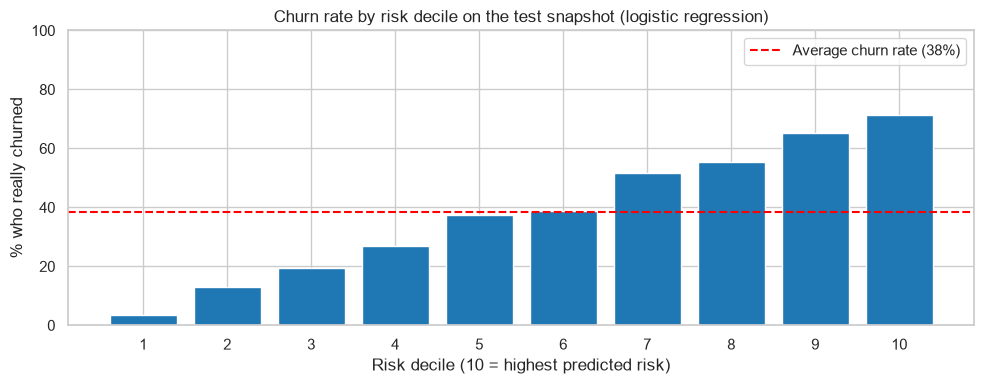

**Takeaway:** On the test snapshot, the 10% of customers with the highest risk churn at 71%, against 38% for all customers (1.9 times better than random), while the 10% with the lowest risk churn at 4%. ROC-AUC is 0.764; the simple rule gets 0.656.

In [8]:
# Split the customers into 10 equal groups by risk (10 = highest risk) and see how many really churned in each
test_scored["decile"] = pd.qcut(test_scored["score"].rank(method="first"), 10, labels=False) + 1
by_decile = test_scored.groupby("decile")["churn"].mean() * 100

fig, ax = plt.subplots()
ax.bar(by_decile.index, by_decile.values, color="tab:blue")
ax.axhline(y_test.mean() * 100, color="red", linestyle="--", label=f"Average churn rate ({y_test.mean():.0%})")
ax.set_title("Churn rate by risk decile on the test snapshot (logistic regression)")
ax.set_xlabel("Risk decile (10 = highest predicted risk)")
ax.set_ylabel("% who really churned")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "churn_by_risk_decile.png", dpi=150, bbox_inches="tight")
plt.show()

best = test_results.loc["Logistic regression"]
takeaway(
    f"On the test snapshot, the 10% of customers with the highest risk churn at {best['top10_churn_rate']:.0%}, "
    f"against {y_test.mean():.0%} for all customers ({best['top10_lift']:.1f} times better than random), "
    f"while the 10% with the lowest risk churn at {by_decile.iloc[0]:.0f}%. "
    f"ROC-AUC is {best['roc_auc']:.3f}; the simple rule gets {test_results.loc['Recency rule', 'roc_auc']:.3f}."
)

## If we contact the highest-risk customers first, how many churners do we reach?

In [9]:
# Number of customers who really churned in each risk decile, starting with decile 10 (highest risk)
churners_per_decile = test_scored.groupby("decile")["churn"].sum().sort_index(ascending=False)

# Running total, as a share of all customers who churned
reach = churners_per_decile.cumsum() / test_scored["churn"].sum() * 100

reach_table = pd.DataFrame({
    "contact the top (% of customers)": (11 - reach.index) * 10,
    "churners reached (%)": reach.round(0).values,
})
reach_table

,contact the top (% of customers),churners reached (%)
0,10,19.0
1,20,36.0
2,30,50.0
3,40,64.0
4,50,74.0
5,60,84.0
6,70,91.0
7,80,96.0
8,90,99.0
9,100,100.0


In [10]:
extra = test_results.loc["Logistic regression", "top10_churn_rate"] - test_results.loc["Recency rule", "top10_churn_rate"]

display(Markdown(f"""
- Three models were compared on the valid snapshot: a recency rule, a logistic regression and LightGBM. The two trained models are far better than the rule (ROC-AUC {results.loc['Logistic regression', 'roc_auc']:.3f} and {results.loc['LightGBM', 'roc_auc']:.3f} against {results.loc['Recency rule', 'roc_auc']:.3f}) and equal to each other, so the simpler **logistic regression** was chosen.
- On the untouched test snapshot the logistic regression gets ROC-AUC {test_results.loc['Logistic regression', 'roc_auc']:.3f} (the rule {test_results.loc['Recency rule', 'roc_auc']:.3f}). The 10% of customers flagged as highest risk churn at {test_results.loc['Logistic regression', 'top10_churn_rate']:.0%} against {y_test.mean():.0%} overall, {extra * 100:.0f} points more than the rule's top 10%.
- Churn rises steadily from {by_decile.iloc[0]:.0f}% in the lowest risk decile to {by_decile.iloc[-1]:.0f}% in the highest.
- Limitation: the churn rate depends on the season (train {y_train.mean():.0%}, valid {y_valid.mean():.0%}, test {y_test.mean():.0%}), so the model predicted {score_test.mean():.0%} on test while the real rate was {y_test.mean():.0%}. Use it to rank customers, not as an exact probability.
"""))


- Three models were compared on the valid snapshot: a recency rule, a logistic regression and LightGBM. The two trained models are far better than the rule (ROC-AUC 0.772 and 0.773 against 0.653) and equal to each other, so the simpler **logistic regression** was chosen.
- On the untouched test snapshot the logistic regression gets ROC-AUC 0.764 (the rule 0.656). The 10% of customers flagged as highest risk churn at 71% against 38% overall, 11 points more than the rule's top 10%.
- Churn rises steadily from 4% in the lowest risk decile to 71% in the highest.
- Limitation: the churn rate depends on the season (train 52%, valid 50%, test 38%), so the model predicted 51% on test while the real rate was 38%. Use it to rank customers, not as an exact probability.
